[Open in Colab](https://colab.research.google.com/github/loem-ms/programming-for-information-systems-site/blob/main/content/downloads/Week_07.ipynb) · [Download notebook](/downloads/Week_07.ipynb) · [Optional ZIP](/downloads/Week_07.zip)

**Before editing:** File → Save a copy in Drive.


# Week 07 · Exceptions and with-block boundaries


(week-07-start)=
[Warm-up](#week-07-class-warm-up) · [Session 1](#week-07-session-1) · [Session 2](#week-07-session-2) · [Session 3](#week-07-project-studio)



(week-07-class-warm-up)=
## Class warm-up · Research 5 exchange

Share your already prepared Research 5 response about **database transactions**. Compare two related writes and what must remain unchanged if the second fails. Keep your source, one question or useful feedback, and your own response. This closes the previously assigned research task; it adds no new assignment.

**My feedback and next step:** …



(week-07-session-1)=
## Session 1 · Python foundations


### A successful return

A function can produce a value, or raise an exception when it cannot produce the promised result.

```python
def subtract_units(available, requested): return available - requested
print(subtract_units(5, 2))  # 3
```


### A guard

Check the required condition before changing state. This example assumes nonnegative integer inputs.

```python
def check_request(available, requested):
    if requested > available: raise ValueError("not enough units")
```


### Interrupted assignment

Python evaluates the right side first. If it raises, assignment does not finish and the old value remains.

```python
remaining = 5
try:
    remaining = int("many")
except ValueError:
    print(remaining)  # 5
```


### Exceptions do not undo ordinary changes

An earlier mutation may survive a later error. Check the state as well as the exception.

```python
state = {"available": 5}
try:
    state["available"] -= 2
    raise ValueError("later failure")
except ValueError:
    print(state["available"])  # 3
```


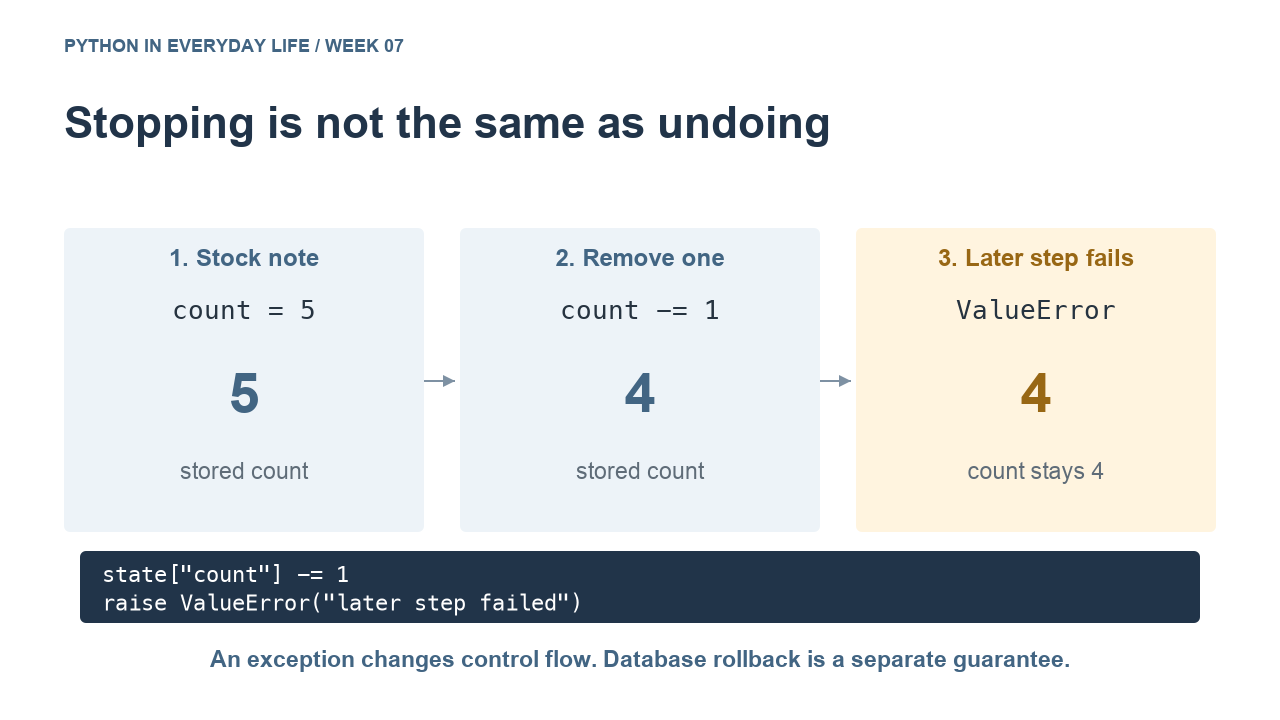


### A with-block

The context manager defines entry and exit behavior. A file manager closes its file. A SQLite connection commits on normal exit or rolls back when an exception escapes; it does not close the connection.

```python
import sqlite3
connection = sqlite3.connect(":memory:")
with connection:
    connection.execute("CREATE TABLE counts(value INTEGER)")
connection.close()
```


### Transaction error handling

Handle a failed transaction outside its with-block. Catching and suppressing the error inside can allow a partial commit. The transaction examples below show the complete boundary.

```python
import sqlite3
connection = sqlite3.connect(":memory:")
try:
    with connection:
        connection.execute("INSERT INTO missing_table VALUES (1)")
except sqlite3.OperationalError:
    print("Transaction failed")
connection.close()
```


### Exact integer counts

This count contract excludes Boolean values. Check the type before the range so text or `None` never reaches a numeric comparison.

```python
value = True
print(type(value) is int, isinstance(value, int))  # False True
```


### Example 1 · Check exact type before a numeric range

`type(value) is int` excludes text, `None` and Boolean `True`. `and` short-circuits: the comparison with zero runs only after the type check succeeds. Predict `False`, `False`, `True`. This guards a stated whole-count contract.


In [ ]:
value = True
print(type(value) is int)
value = "2"
print(type(value) is int and value > 0)
value = 2
print(type(value) is int and value > 0)


### Example 2 · A raised exception prevents a `return`

The guard runs before `return`. Zero triggers `ValueError`, so the caller enters its handler instead of receiving a value. Predict Refused: positive count required. This is ordinary control flow, not database rollback.


In [ ]:
def positive(value):
    if type(value) is not int or value <= 0:
        raise ValueError("positive count required")
    return value

try:
    print(positive(0))
except ValueError as error:
    print("Refused:", error)


### Example 3 · An exception does not undo ordinary mutation

This deliberately changes a dictionary before raising. The handler catches the error but does not restore the dictionary. Predict 4, not 5. A database transaction provides a specific rollback guarantee; Python exceptions alone do not.


In [ ]:
state = {"count": 5}
try:
    state["count"] -= 1
    raise ValueError("later step failed")
except ValueError:
    print(state["count"])
assert state["count"] == 4


### Combined example


In [ ]:
def subtract_units(available, requested):
    if requested > available:
        raise ValueError("not enough units")
    return available - requested

remaining = 5
try:
    remaining = subtract_units(remaining, 7)
    print("Assignment finished")
except ValueError as error:
    print("Error:", str(error))
print("Remaining:", remaining)
assert remaining == 5
assert subtract_units(5, 2) == 3


The error message appears, Assignment finished does not, and Remaining is 5. The failed call never supplied a new value for assignment. The independent successful call returns 3. Neither call mutates a shared object.


(week-07-session-2)=
## Session 2 · Hands-on practice

(week-07-practice-week-07)=
Five exercises: P1–P3 are core; P4–P5 are optional. Record an expected result, observed result and explanation for each completed exercise.


### P1 · Write a positive-count guard

**Core**

Easy. Write `positive_count(value)`: accept a positive exact `int` and `return` it; otherwise `raise` `ValueError`. Predict results for 2, 0 and `True`. Hint: inspect the type before the range and put the successful `return` after the guards.

In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P2 · Write the caller and handler

**Core**

Easy. Start `count` at 5. Use your `positive_count` in a `try` block to assign `positive_count(0)` to `count`. Catch `ValueError` outside the call, print a refusal reason, then assert `count` is still 5. Repeat separately with 2 and expect 2. Hint: assignment finishes only after a successful return; the handler does not retry.

In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P3 · Write the guarded calculation

**Core**

Write `reserve_count(available, requested, reviewed)` with separate guards for missing review, invalid `requested` type/count, and shortage. Return the remaining count only on success. Use `type(requested) is int` so `True` is refused. Assume `available` is a valid nonnegative integer. Write a `try/except` caller that retains 5 after refusal. Check `(5,2,True)` → 3 and refusal for unreviewed, 0, `True` and 6. Include successful exact-availability and invalid-type tests, then let a peer choose a new case.

In [ ]:
def reserve_count(available, requested, reviewed):
    # Write guards, then return the remaining count.
    raise NotImplementedError

# Write a successful assertion and a caller that catches a refusal.


**Expected:** …  **Observed:** …  **Explanation:** …


### P4 · Write an atomic pair of updates

**Optional**

Optional for learners who finish the core. Keep the supplied setup and snapshot helper. Write `reserve_pair(db, first, second, interrupt=False)`. Counts here are already positive integers. Inside one `with db` block, loop through T01/`first` and T02/`second`, execute a guarded `UPDATE` with placeholders, and raise `ValueError` when `rowcount` is not 1. After both updates, raise `RuntimeError` if `interrupt` is `True`. Do not catch inside the block. Fresh (2,1) leaves 3 and 1. Fresh (2,3) must leave 5 and 2. use the SQL hint, not a completed function.

In [ ]:
import sqlite3

def new_practice_db():
    db = sqlite3.connect(":memory:")
    db.execute("CREATE TABLE practice_stock(batch TEXT PRIMARY KEY, available INTEGER)")
    with db:
        db.executemany("INSERT INTO practice_stock VALUES (?, ?)", [("T01", 5), ("T02", 2)])
    return db

def snapshot(db):
    return db.execute("SELECT batch, available FROM practice_stock ORDER BY batch").fetchall()

def reserve_pair(db, first, second, interrupt=False):
    # SQL hint: UPDATE practice_stock SET available=available-?
    # WHERE batch=? AND available>=?
    # Write the transaction, loop, guards and optional failure.
    raise NotImplementedError


**Expected:** …  **Observed:** …  **Explanation:** …


### P5 · Write failure-state tests

**Optional**

Optional for learners who finish the core. Reuse your helpers. Write three independent tests from fresh databases: success (2,1), shortage on the second batch (2,3), and injected interruption after both updates. For each failure assert the exception type and the complete snapshot. Include an `else` branch that fails if no exception occurs, and close each database. Expected success is [(T01,3),(T02,1)]; both failures retain [(T01,5),(T02,2)]. Explain why testing only the first failure message is insufficient. Include peer review.

In [ ]:
# Reuse new_practice_db, snapshot and your reserve_pair.
# Write three tests below. Each must start with a fresh database.
# For failure tests: save before, call inside try, catch the expected
# exception, fail in else, then compare the complete after snapshot.


**Expected:** …  **Observed:** …  **Explanation:** …


Optional: deliberately catch an injected error inside the transaction in an isolated copy. Predict the partial state and show that your unchanged-state assertion detects it. Keep the correct version.


(week-07-project-studio)=
## Session 3 · Project studio


### Project files

Run this collapsed cell once, and again after a runtime restart. No ZIP, upload or network download is needed. Existing support files are preserved. Save created or edited files separately.


In [ ]:
# @title Prepare the course files (run after each runtime restart)
# Supplied programs, starter policy, CSV fixtures and diagrams are embedded here.
# This cell uses only Python's standard library. It makes no network request.
import base64 as _course_base64
import hashlib as _course_hashlib
import json as _course_json
import os as _course_os
from pathlib import Path as _CoursePath
import zlib as _course_zlib

_course_payload = '...'
_course_raw = _course_zlib.decompress(_course_base64.b64decode(_course_payload))
if _course_hashlib.sha256(_course_raw).hexdigest() != 'b46725a950efe16c2e1841abb46ccf8287106b1a573d8b1987fc0aa0ccfd8f2d':
    raise ValueError("Embedded course files are damaged; get a fresh notebook.")
_course_files = _course_json.loads(_course_raw)
_course_key = 'week_07_b46725a950ef'
_course_roots = globals().setdefault("_course_workspace_roots", {})
if _course_key in _course_roots:
    _course_root = _CoursePath(_course_roots[_course_key])
elif all((_CoursePath.cwd() / _name).is_file() for _name in _course_files):
    # A complete extracted offline pack can be used in place.
    _course_root = _CoursePath.cwd()
else:
    _course_root = _CoursePath.cwd() / ".course_files" / _course_key
if _course_root.is_symlink() or any(_p.is_symlink() for _p in _course_root.parents):
    raise ValueError("Refusing a symbolic link in the course workspace")
_course_root.mkdir(parents=True, exist_ok=True)
for _name, _encoded in _course_files.items():
    _relative = _CoursePath(_name)
    if _relative.is_absolute() or ".." in _relative.parts:
        raise ValueError("Unsafe embedded support path")
    _target = _course_root / _relative
    if _target.is_symlink() or any(_p.is_symlink() for _p in _target.parents):
        raise ValueError("Refusing a symbolic link in the course workspace")
    _target.parent.mkdir(parents=True, exist_ok=True)
    if _target.exists() and not _target.is_file():
        raise ValueError("Course support path is not a regular file: " + str(_target))
    if not _target.exists():
        with _target.open("xb") as _output:
            _output.write(_course_base64.b64decode(_encoded))
_course_workspace_roots[_course_key] = str(_course_root.resolve())
_course_os.chdir(_course_root)
print("Course files ready:", _CoursePath.cwd())
print("Existing files were kept. Rerunning setup never replaces your edits.")
print("Save your notebook and download created/edited files before the runtime ends.")


### The people’s task this week

**Someone needs help:** A booking must not leave only part of a request set aside.

**Your small part:** Accept the whole booking, or leave the records unchanged if it cannot finish.

![Week 7: the person’s need, your task, and the useful result.](assets/diagrams/course_week_07.svg)

**Picture one example:** One item unavailable → all counts stay unchanged.

**A useful result:** Another volunteer sees consistent available counts.

Use the supplied starting files and the task instructions below. The diagram explains the purpose; it adds no separate assignment.

**Final-project connection:** The final planning form only estimates and labels. Actual reservations use the supplied all-or-nothing engine. Preserve its human-review and unchanged-state checks when testing your approved improvement.


In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/course_week_07.svg'))


### Example 1 · One guarded update before a multi-line reservation

The `WHERE` condition is checked as part of the `UPDATE`. `rowcount` reports matching changed rows; zero is not an automatic Python exception. Predict 1 and (3,). No reservation table or review decision is involved in this tiny example.


In [ ]:
import sqlite3
example_db = sqlite3.connect(":memory:")
try:
    example_db.execute("CREATE TABLE stock(id TEXT PRIMARY KEY, available INTEGER)")
    with example_db:
        example_db.execute("INSERT INTO stock VALUES (?, ?)", ("A", 5))
    with example_db:
        changed = example_db.execute("UPDATE stock SET available = available - ? WHERE id = ? AND available >= ?", (2, "A", 2))
        print(changed.rowcount)
    row = example_db.execute("SELECT available FROM stock WHERE id = ?", ("A",)).fetchone()
    print(row)
    assert row == (3,)
finally:
    example_db.close()


### Example 2 · See rollback on one table first

The setup insert is committed before the experiment. The deliberate error escapes `with`, so SQLite rolls back the `UPDATE` before the outside handler runs. Predict (5,). This same boundary later encloses all reservation tables.


In [ ]:
import sqlite3
example_db = sqlite3.connect(":memory:")
try:
    example_db.execute("CREATE TABLE stock(available INTEGER)")
    with example_db:
        example_db.execute("INSERT INTO stock VALUES (5)")
    try:
        with example_db:
            example_db.execute("UPDATE stock SET available = available - 2")
            raise ValueError("later step failed")
    except ValueError:
        pass
    row = example_db.execute("SELECT available FROM stock").fetchone()
    print(row)
    assert row == (5,)
finally:
    example_db.close()


### Project application reference examples

These saved lesson examples support the project tasks below. Run the one you need; Python core practice is in Session 2.

**`rowcount`: one row changed**

In [ ]:
import sqlite3
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE offers(id TEXT, available INT)")
db.execute("INSERT INTO offers VALUES ('DEMO',5)")
cur = db.execute(
    "UPDATE offers SET available=available-? "
    "WHERE id=? AND available>=?", (2, "DEMO", 2))
assert cur.rowcount == 1
row = db.execute("SELECT * FROM offers").fetchone()
assert row[-1] == 3
db.close()


**`rowcount`: no row matched**

In [ ]:
import sqlite3
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE offers(available INT)")
db.execute("INSERT INTO offers VALUES (3)")
cur = db.execute(
    "UPDATE offers SET available=available-? "
    "WHERE available>=?", (4, 4))
assert cur.rowcount == 0
row = db.execute("SELECT * FROM offers").fetchone()
assert row[-1] == 3
db.close()


### Project context

In this fictional case, related reservation changes must succeed together or leave the database unchanged. Reservation does not establish collection or delivery.



### A saved plan must not become half an approved reservation

Campus Food Rescue can preserve a planning document. The coordinator now authorizes an actual request against reviewed batch availability. A **reservation** reduces reservable containers and records a complete request. It is still not a collection or delivery; those require explicit later events.

The request's supplied `reviewed` flag records a human decision about suitability, partner arrangements and a collection window. An unreviewed request is held without writes. A shortage on any line rejects the whole reservation, restoring earlier availability changes and leaving no header or lines.

![Required writes share one transaction, with commit or rollback after the attempt.](assets/diagrams/w07_transaction.svg)

Learn guarded SQL updates, `rowcount`, exception boundaries and state tests. [Python foundations](https://loem-ms.github.io/programming-for-information-systems-site/content/learning-materials/python-basics/): exceptions, SQLite and [unittest](https://loem-ms.github.io/programming-for-information-systems-site/content/learning-materials/python-basics/#python-basics-b17).

In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/w07_transaction.svg'))


### Specify success and failure

Predict all affected records for a reviewed request whose second batch is unavailable, and for an unreviewed request. Mark the transaction boundary.

### Reservation input and state contract

Use positive exact integer container counts for reservations. Validate the supplied review flag and the batch identity; then group availability changes, the reservation header and line snapshots in one transaction.

### Distinguish success, shortage and authority

Explain both printed rows. Why does successful SQL not establish coordinator approval? What state observations are needed when a later line fails?

In [ ]:
# Your implementation, prediction or evidence goes here.

### Complete an atomic reservation

Implement the guarded movement and line snapshots, then inject a failure after the first complete line and compare database states.


(week-07-project-task)=
### Student lab · implement the missing behavior

Opening availability is four Q11 containers at three portions each, and four Q12 containers at five portions each. Implement `reserve`. Test: (1) unreviewed Q11:1; (2) reviewed Q11:1 plus Q12:7; (3) a reviewed valid pair with injected failure; (4) reviewed Q11:2 plus Q12:1 successfully. Save all three table snapshots before and after. Preserve the portion-unit snapshot. Do not mark collection or delivery.

In [ ]:
import sqlite3

db = sqlite3.connect(":memory:")
db.executescript("CREATE TABLE offer_batches(batch_id TEXT PRIMARY KEY, portions_per_container INTEGER, available_containers INTEGER);\nCREATE TABLE reservations(request_id TEXT PRIMARY KEY, reviewed INTEGER, status TEXT);\nCREATE TABLE reservation_lines(request_id TEXT, line_no INTEGER, batch_id TEXT, containers INTEGER, portions_per_container_snapshot INTEGER, PRIMARY KEY(request_id,line_no));\nINSERT INTO offer_batches VALUES ('Q11',3,4),('Q12',5,4);\n")

def snapshot():
    return {
        "offers": db.execute("SELECT * FROM offer_batches ORDER BY batch_id").fetchall(),
        "headers": db.execute("SELECT * FROM reservations ORDER BY request_id").fetchall(),
        "lines": db.execute("SELECT * FROM reservation_lines ORDER BY request_id,line_no").fetchall(),
    }

def reserve(request_id, reviewed, lines, inject_failure=False):
    raise NotImplementedError("Implement review, validation, guarded writes and snapshots")

print("Opening state:", snapshot())
# Add implementation and tests. Catch failures outside the transaction.
# Close db after retaining evidence; rerunning setup makes a new independent fixture.

### Repeat tests outside a notebook kernel

From `learning_materials/`, run the supplied planning-program suite:

**Choose the course interpreter.** In terminal examples, `python` means the Python used for your course environment. If setup created `.venv`, replace it with the operating-system-specific path in the [program guide](https://loem-ms.github.io/programming-for-information-systems-site/content/learning-materials/programs/readme/#choose-the-course-interpreter). That path changes when you change directories. In a notebook, `import sys; print(sys.executable)` shows the interpreter in use.

```sh
python -m unittest discover -s programs -p "test_*.py"
```

`-m unittest` runs Python's test runner; `discover` finds test modules; `-s programs` chooses the search directory, not a new working directory. The supplied tests cover practice programs and models. They do not automatically test your reservation implementation.

In a test method, `with self.assertRaises(ValueError):` checks the expected failure. A separate equality assertion checks unchanged state. Neither a skipped test nor a printed refusal proves rollback. A full state snapshot is stronger than an alias such as `before = live_state` pointing at a mutable object.

### Investigate a failed reservation

A peer supplies a new failure case and checks your state evidence. Explain where failures are raised and caught, and identify one project need.

### Independent challenge and regression evidence

Test an invalid zero count, an unknown batch after a valid first line, and a repeated batch that exhausts availability across two lines. Explain why retrying a committed request ID is not the same as rolling back a failed attempt.

In [ ]:
# Your implementation, prediction or evidence goes here.

### Individual explanation and next need

Explain a decision, one observed result, and a limitation or revision. Name the difference among offered, reserved, collected and delivered quantities.

In [ ]:
# Your implementation, prediction or evidence goes here.

### Research 6 · how to check automated or AI output

**Research how to check automated or AI output.** Find out how to verify an automated answer against its original source. You may use the supplied example instead of a live AI tool.

**Possible directions:** Compare fields, units, missing information and unsupported claims. Explain what you would accept, correct or ask about.

**A short summary example:** “The source says “12 boxes offered”; the output says “12 portions collected”. The unit and collection claim are unsupported, so ask for clarification.”

Briefly explain what you found in your own words and name the sources you used. You may use a short note or slides; the example above is guidance, not a required format. Prepare after class and bring one finding to the Week 8 class warm-up before Session 1.

The course Research guide explains AI use and submission arrangements.

In [ ]:
# Your implementation, prediction or evidence goes here.

### Optional supplied project references

These original examples explain the project application. Consult the reference you need; they are not extra Python core exercises.

### Let failure escape the transaction before handling it

With this notebook's SQLite connection configuration, normal exit from `with db:` commits pending writes; an exception escaping the block rolls them back. The block does not close the connection. Catch the failure outside the transaction, record its reason and then inspect the state.

If a required step fails but an inner `except` suppresses the exception and returns normally, earlier writes may commit. A printed refusal does not undo them. Python list changes, sent messages and printed sheets are not automatically rolled back with SQLite.

In [ ]:
import sqlite3

demo = sqlite3.connect(":memory:")
try:
    demo.execute("CREATE TABLE availability(containers INTEGER)")
    with demo:
        demo.execute("INSERT INTO availability VALUES (5)")
    before = demo.execute("SELECT containers FROM availability").fetchone()
    try:
        with demo:
            demo.execute("UPDATE availability SET containers=containers-2")
            raise RuntimeError("Practice interruption after first write")
    except RuntimeError as error:
        print("Follow-up:", str(error))
    after = demo.execute("SELECT containers FROM availability").fetchone()
    assert before == after == (5,)
    print("Before / after:", before, after)
finally:
    demo.close()

### Make the availability condition part of the write

A guarded update says “subtract the requested containers only if enough remain.” `cursor.rowcount` tells whether the intended row changed. Zero affected rows does not automatically raise; the caller must raise when the operation cannot complete. Zero alone also cannot distinguish an unknown batch from a shortage, so use appropriate lookup evidence.

The repeated quantity in the parameter tuple has two roles: amount to subtract and minimum required availability. A positive-count check is still necessary: subtracting a negative count would increase availability.

In [ ]:
import sqlite3

demo = sqlite3.connect(":memory:")
try:
    demo.execute("CREATE TABLE offers(batch_id TEXT PRIMARY KEY, available_containers INTEGER)")
    with demo:
        demo.execute("INSERT INTO offers VALUES (?, ?)", ("DEMO", 5))
    for requested, expected_changed, expected_remaining in [(2, 1, 3), (4, 0, 3)]:
        with demo:
            cursor = demo.execute("UPDATE offers SET available_containers=available_containers-? WHERE batch_id=? AND available_containers>=?", (requested, "DEMO", requested))
        remaining = demo.execute("SELECT available_containers FROM offers WHERE batch_id=?", ("DEMO",)).fetchone()[0]
        assert (cursor.rowcount, remaining) == (expected_changed, expected_remaining)
        print(requested, cursor.rowcount, remaining)
finally:
    demo.close()


(week-07-finish)=
### Finish: check, save and decide what comes next

- [ ] I can explain the Python concept used this week.
- [ ] I kept a prediction, an observed result and an explanation for the core practice.
- [ ] I completed the required project behavior and checks described above.
- [ ] I recorded one peer observation or individual finding, plus a revision or defended decision.
- [ ] I stated one limitation or question that requires a person.

**Save:** save this notebook and any project files you changed. Keep a separate backup. Re-run the relevant completed cells from a known starting state before claiming the result; unresolved TODOs and skipped tests are not evidence of completion. Send assessed work to [submit.progmis@gmail.com](mailto:submit.progmis@gmail.com); exact deadlines and file names remain separately announced.

**Stop point:** when the required practice and project evidence are complete, save and stop. Optional follow-ups can wait.

**Next:** Week 8: report distinct lifecycle stages and review donor-message candidates.

[Back to Start Here](#week-07-start) · [Review the Python explanation](#week-07-session-1) · [Return to Project Studio](#week-07-project-studio)